# 1. Configuración, Modelo y Preparación de Datos (IID)

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
import copy

In [2]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # Capa 1: Entrada 3 canales (RGB), salida 32 filtros. Imagen 32x32 -> 16x16 tras pooling
        self.layer1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        # Capa 2: Entrada 32, salida 64. Imagen 16x16 -> 8x8 tras pooling
        self.layer2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        # Capa 3: Entrada 64, salida 64. Imagen 8x8 -> 4x4 tras pooling
        self.layer3 = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        # Clasificador: 64 filtros de 4x4 = 1024 neuronas de entrada
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 512),
            nn.ReLU(),
            nn.Linear(512, 10) # 10 clases de CIFAR-10
        )

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.fc(x)
        return x

Instanciación de modelos

In [3]:
# 1. Definición del Hardware (Esto define 'device')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Carga de CIFAR-10 y creación de Dataloaders (Esto define 'testloader' y 'client_loaders')
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.2023, 0.1994, 0.201])
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = DataLoader(testset, batch_size=100, shuffle=False)

# 3. Partición de datos para 5 clientes
num_clients = 5
partition_size = len(trainset) // num_clients
partitions = random_split(trainset, [partition_size] * num_clients)
# Cada client loader tiene una partición disjunta de los datos.
client_loaders = [DataLoader(part, batch_size=64, shuffle=True) for part in partitions]

# 4. Instanciación de Modelos (Esto define 'global_model' y 'local_models')
# Asegúrate de haber ejecutado la celda de la clase SimpleCNN antes que esta
global_model = SimpleCNN().to(device)
local_models = [SimpleCNN().to(device) for _ in range(num_clients)]

print(f"Entorno listo en {device}. Datos cargados y modelos instanciados.")
client_loaders = [DataLoader(part, batch_size=64, shuffle=True) for part in partitions]

Files already downloaded and verified


/home/anton/Escritorio/GIA-Apuntes/4º curso/2º cuatri/slesi/practicas/Slesi/.venv/lib/python3.12/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Files already downloaded and verified
Entorno listo en cuda. Datos cargados y modelos instanciados.


## 2. Entrenamiento Local

In [4]:
def train_local(model, train_loader, epochs=1, lr=0.01):
    model.train()
    criterion = nn.CrossEntropyLoss()
    # Importante: Usamos SGD local para cada cliente
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    
    for epoch in range(epochs):
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
    
    # Devolvemos el estado del modelo (pesos)
    return model.state_dict()

Función de agregación (servidor central)

In [5]:
def federated_averaging(local_weights):
    # Usamos el primer cliente como base para la estructura del dict
    avg_weights = copy.deepcopy(local_weights[0])
    
    for key in avg_weights.keys():
        for i in range(1, len(local_weights)):
            avg_weights[key] += local_weights[i][key]
        # Promedio simple ya que las particiones son IID y del mismo tamaño
        avg_weights[key] = torch.div(avg_weights[key], len(local_weights))
    
    return avg_weights

## Bucle de entrenamiento (servidor central)

In [6]:
def evaluate_model(model, test_loader):
    model.eval() # Ponemos el modelo en modo evaluación (desactiva Dropout/BatchNorm)
    correct = 0
    total = 0
    
    # Desactivamos el cálculo de gradientes para ahorrar memoria y tiempo
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
    accuracy = 100 * correct / total
    return accuracy

In [7]:
# Historial para la gráfica posterior
history = []

print("Iniciando entrenamiento federado...")

for round_num in range(1, 11):
    local_weights_list = []
    
    # Obtener los pesos actuales del modelo global
    global_weights = global_model.state_dict()
    
    # Simular la distribución a los 5 clientes
    for i in range(num_clients):
        # 1. Sincronizar el modelo local con el global
        local_models[i].load_state_dict(global_weights)
        
        # 2. Entrenamiento local
        weights = train_local(local_models[i], client_loaders[i], epochs=1) # 1 para testeo. Irl serían más
        local_weights_list.append(weights)
    
    # 3. Agregación en el servidor
    new_global_weights = federated_averaging(local_weights_list)
    global_model.load_state_dict(new_global_weights)
    
    # 4. Evaluación del modelo global en el set de TEST
    accuracy = evaluate_model(global_model, testloader)
    history.append(accuracy)
    
    print(f"Ronda {round_num:02d} | Test Accuracy: {accuracy:.4f}")

print("\nEntrenamiento completado.")

Iniciando entrenamiento federado...
Ronda 01 | Test Accuracy: 39.4300
Ronda 02 | Test Accuracy: 48.5400
Ronda 03 | Test Accuracy: 53.5600
Ronda 04 | Test Accuracy: 57.0400
Ronda 05 | Test Accuracy: 60.2700
Ronda 06 | Test Accuracy: 63.3000
Ronda 07 | Test Accuracy: 65.9100
Ronda 08 | Test Accuracy: 67.8200
Ronda 09 | Test Accuracy: 69.3200
Ronda 10 | Test Accuracy: 71.0500

Entrenamiento completado.


--- Iniciando entrenamiento federado BAJO ATAQUE ---
Ronda 01 | Test Accuracy (Envenenado): 4.6500%
Ronda 02 | Test Accuracy (Envenenado): 10.0000%
Ronda 03 | Test Accuracy (Envenenado): 10.0000%
Ronda 04 | Test Accuracy (Envenenado): 10.0000%
Ronda 05 | Test Accuracy (Envenenado): 10.0000%
Ronda 06 | Test Accuracy (Envenenado): 10.0000%
Ronda 07 | Test Accuracy (Envenenado): 10.0000%
Ronda 08 | Test Accuracy (Envenenado): 10.0000%
Ronda 09 | Test Accuracy (Envenenado): 10.0000%
Ronda 10 | Test Accuracy (Envenenado): 10.0000%


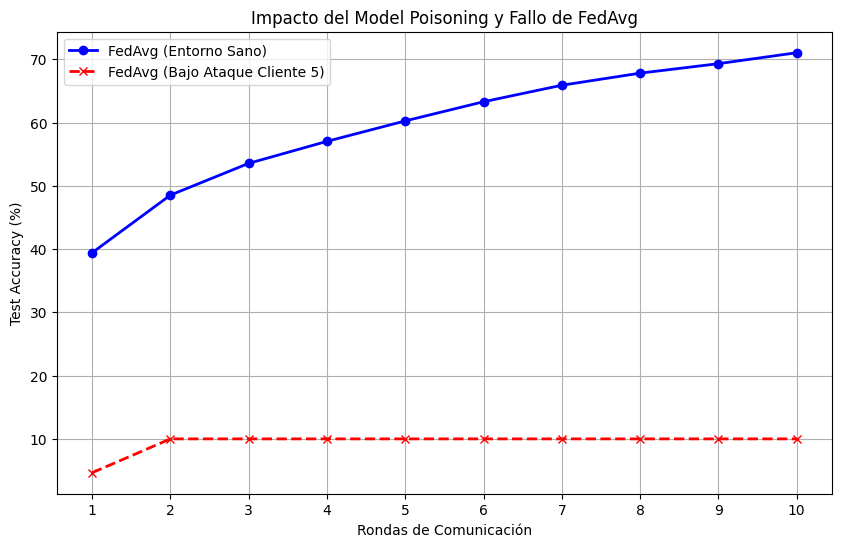

In [8]:
import matplotlib.pyplot as plt

# 1. Redefinimos el entrenamiento local para incluir el "botón" de ataque
def train_local_poisoned(model, train_loader, epochs=1, lr=0.01, is_malicious=False):
    model.train()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    
    for epoch in range(epochs):
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            #ATAQUE 1: Inversión de Etiquetas (Label Flipping)
            if is_malicious:
                labels = (labels + 1) % 10
                
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
    
    #ATAQUE 2: Escalamiento de Pesos (Weight Scaling)
    local_weights = copy.deepcopy(model.state_dict())
    if is_malicious:
        for key in local_weights.keys():
            local_weights[key] = local_weights[key] * 100.0
            
    return local_weights


# 2. Reiniciamos los modelos para una simulación limpia bajo ataque
global_model_poisoned = SimpleCNN().to(device)
local_models_poisoned = [SimpleCNN().to(device) for _ in range(num_clients)]
history_poisoned = []     

print("--- Iniciando entrenamiento federado BAJO ATAQUE ---")

for round_num in range(1, 11):
    local_weights_list = []
    global_weights = global_model_poisoned.state_dict()
    
    for i in range(num_clients):
        local_models_poisoned[i].load_state_dict(global_weights)
        
        # El cliente 5 (índice 4) es el nodo malicioso
        is_malicious = True if i == 4 else False
        
        weights = train_local_poisoned(local_models_poisoned[i], client_loaders[i], epochs=1, is_malicious=is_malicious)
        local_weights_list.append(weights)
    
    # Agregación (El servidor sigue usando FedAvg, creyendo que todos son buenos)
    new_global_weights = federated_averaging(local_weights_list)
    global_model_poisoned.load_state_dict(new_global_weights)
    
    # Evaluación
    accuracy = evaluate_model(global_model_poisoned, testloader)
    history_poisoned.append(accuracy)
    
    print(f"Ronda {round_num:02d} | Test Accuracy (Envenenado): {accuracy:.4f}%")

# 3. Generación de la gráfica comparativa
plt.figure(figsize=(10, 6))
# 'history' contiene los datos de tu celda anterior sana
plt.plot(range(1, 11), history, label='FedAvg (Entorno Sano)', marker='o', color='blue', linewidth=2)
# 'history_poisoned' contiene los datos del ataque
plt.plot(range(1, 11), history_poisoned, label='FedAvg (Bajo Ataque Cliente 5)', marker='x', color='red', linewidth=2, linestyle='--')

plt.title('Impacto del Model Poisoning y Fallo de FedAvg')
plt.xlabel('Rondas de Comunicación')
plt.ylabel('Test Accuracy (%)')
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.show()

In [9]:
def trimmed_mean(local_weights, trim_ratio=0.2):
    # trim_ratio 0.2 con 5 clientes significa descartar 1 por arriba y 1 por abajo
    avg_weights = copy.deepcopy(local_weights[0])
    num_clients = len(local_weights)
    trim_num = int(num_clients * trim_ratio) # 5 * 0.2 = 1
    
    for key in avg_weights.keys():
        # Apilamos los pesos de todos los clientes para este parámetro específico
        stacked_weights = torch.stack([local_weights[i][key] for i in range(num_clients)], dim=0)
        
        # Los ordenamos de menor a mayor
        sorted_weights, _ = torch.sort(stacked_weights, dim=0)
        
        # Cortamos los extremos (el 1 más bajo y el 1 más alto)
        if trim_num > 0:
            trimmed_weights = sorted_weights[trim_num : num_clients - trim_num]
            # Promediamos los 3 restantes
            avg_weights[key] = torch.mean(trimmed_weights, dim=0)
        else:
            avg_weights[key] = torch.mean(stacked_weights, dim=0)
            
    return avg_weights

--- Iniciando entrenamiento federado BAJO ATAQUE ---
Ronda 01 | Test Accuracy (Envenenado): 39.3900%
Ronda 02 | Test Accuracy (Envenenado): 47.4100%
Ronda 03 | Test Accuracy (Envenenado): 54.4200%
Ronda 04 | Test Accuracy (Envenenado): 58.8600%
Ronda 05 | Test Accuracy (Envenenado): 61.4000%
Ronda 06 | Test Accuracy (Envenenado): 64.4700%
Ronda 07 | Test Accuracy (Envenenado): 67.3400%
Ronda 08 | Test Accuracy (Envenenado): 68.3900%
Ronda 09 | Test Accuracy (Envenenado): 69.5100%
Ronda 10 | Test Accuracy (Envenenado): 71.0200%


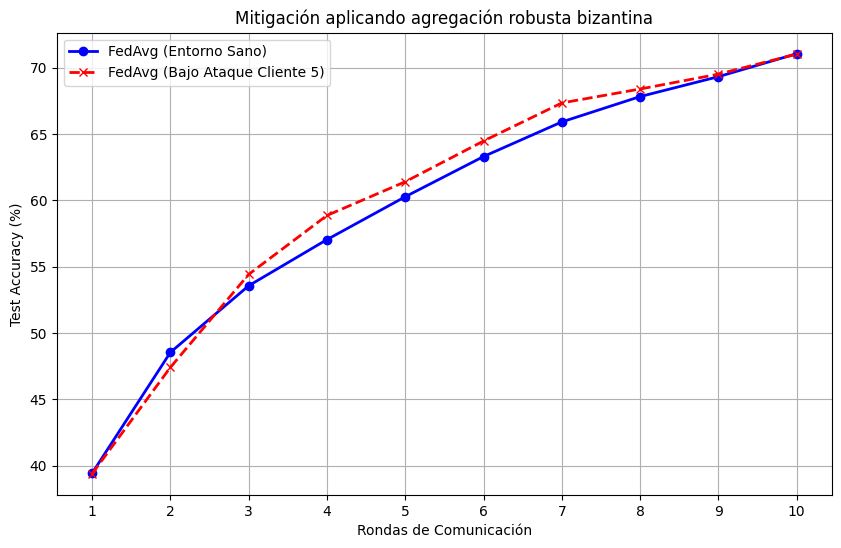

In [10]:
# 1. Redefinimos el entrenamiento local para incluir el "botón" de ataque
def train_local_poisoned(model, train_loader, epochs=1, lr=0.01, is_malicious=False):
    model.train()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    
    for epoch in range(epochs):
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            #ATAQUE 1: Inversión de Etiquetas (Label Flipping)
            if is_malicious:
                labels = (labels + 1) % 10
                
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
    
    #ATAQUE 2: Escalamiento de Pesos (Weight Scaling)
    local_weights = copy.deepcopy(model.state_dict())
    if is_malicious:
        for key in local_weights.keys():
            local_weights[key] = local_weights[key] * 100.0
            
    return local_weights


# 2. Reiniciamos los modelos para una simulación limpia bajo ataque
global_model_poisoned = SimpleCNN().to(device)
local_models_poisoned = [SimpleCNN().to(device) for _ in range(num_clients)]
history_poisoned = []     

print("--- Iniciando entrenamiento federado BAJO ATAQUE ---")

for round_num in range(1, 11):
    local_weights_list = []
    global_weights = global_model_poisoned.state_dict()
    
    for i in range(num_clients):
        local_models_poisoned[i].load_state_dict(global_weights)
        
        # El cliente 5 (índice 4) es el nodo malicioso
        is_malicious = True if i == 4 else False
        
        weights = train_local_poisoned(local_models_poisoned[i], client_loaders[i], epochs=1, is_malicious=is_malicious)
        local_weights_list.append(weights)
    
    # Agregación (El servidor sigue usando FedAvg, creyendo que todos son buenos)
    new_global_weights = trimmed_mean(local_weights_list)
    global_model_poisoned.load_state_dict(new_global_weights)
    
    # Evaluación
    accuracy = evaluate_model(global_model_poisoned, testloader)
    history_poisoned.append(accuracy)
    
    print(f"Ronda {round_num:02d} | Test Accuracy (Envenenado): {accuracy:.4f}%")

# 3. Generación de la gráfica comparativa
plt.figure(figsize=(10, 6))
# 'history' contiene los datos de tu celda anterior sana
plt.plot(range(1, 11), history, label='FedAvg (Entorno Sano)', marker='o', color='blue', linewidth=2)
# 'history_poisoned' contiene los datos del ataque
plt.plot(range(1, 11), history_poisoned, label='FedAvg (Bajo Ataque Cliente 5)', marker='x', color='red', linewidth=2, linestyle='--')

plt.title('Mitigación aplicando agregación robusta bizantina')
plt.xlabel('Rondas de Comunicación')
plt.ylabel('Test Accuracy (%)')
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.show()